# Klasifikasi Domain Berbasis Punycode untuk Identifikasi Serangan Phishing Menggunakan Naive Bayes

## Notebook Final — Studi Eksperimen dengan Data Sintetis dan Nyata

Notebook final ini merupakan dokumen eksperimen utama sekaligus dokumentasi penelitian. Alur mencakup kajian penelitian terdahulu, audit data, pembentukan data sintetis, EDA, preprocessing, feature engineering URL/Punycode, perbandingan keluarga Naive Bayes, evaluasi real-only, learning curve, ablation study, penyimpanan model, dan pengujian prediksi. Model aplikasi dipilih berdasarkan validasi dan dievaluasi pada real-only test yang tidak digunakan saat training maupun tuning.

## 1. Penelitian terdahulu dan posisi penelitian

| Penelitian | Cara mendeteksi | Keterbatasan/celah yang diambil |
|---|---|---|
| Le et al. (2018), **URLNet** | CNN pada karakter dan kata URL untuk mempelajari representasi URL secara end-to-end. | Kuat untuk pola URL umum, tetapi Punycode/homograph bukan fokus eksplisit dan komputasinya lebih berat daripada Naive Bayes. |
| Mamun et al. (2019), **Using Lexical Features for Malicious URL Detection** | Fitur leksikal URL untuk keputusan real-time tanpa memuat halaman. | Fokus malicious URL umum; hubungan skrip Unicode, IDNA, dan homograph perlu lapisan khusus. |
| Suzuki et al. (2019), **ShamFinder** | Membentuk basis data homoglyph otomatis dan mencari IDN yang menyerupai domain lain. | Sangat relevan untuk homograph, tetapi bukan klasifikasi phishing URL lengkap dengan path/query. |
| Sawabe et al. (2019) | OCR membandingkan tampilan IDN dengan domain legitimate sehingga tidak hanya bergantung pada tabel manual. | Memerlukan pemrosesan visual/OCR; penelitian ini memilih skeleton Unicode yang lebih ringan. |
| Yazdani et al. (2020) | Tabel homoglyph yang diperluas + karakteristik domain + active DNS measurements. | Membutuhkan data DNS aktif; penelitian ini sengaja dapat berjalan offline hanya dari URL. |
| Hu et al. (2021) | Mengevaluasi kebijakan browser terhadap mixed-script, skeleton, confusable, dan tampilan Punycode. | Pertahanan browser tidak selalu sama dan bukan model klasifikasi data phishing. |
| Tupsamudre et al. (2021), **PhishMatch** | Pertahanan berlapis: exact/approximate string matching, n-gram, whitelist, konteks, dan ML. | Menguatkan alasan pendekatan berlapis; penelitian ini memfokuskan kontribusi pada IDN/Punycode dan Naive Bayes ringan. |

### Sumber primer

1. [URLNet, arXiv:1802.03162](https://arxiv.org/abs/1802.03162)  
2. [Using Lexical Features for Malicious URL Detection, arXiv:1910.06277](https://arxiv.org/abs/1910.06277)  
3. [ShamFinder, arXiv:1909.07539](https://arxiv.org/abs/1909.07539)  
4. [Detection Method of Homograph IDNs with OCR](https://www.jstage.jst.go.jp/article/ipsjjip/27/0/27_536/_article/-char/en)  
5. [A Case of Identity, DOI 10.1109/EuroSPW51379.2020.00082](https://doi.org/10.1109/EuroSPW51379.2020.00082)  
6. [Assessing Browser-level Defense against IDN-based Phishing, USENIX Security 2021](https://www.usenix.org/conference/usenixsecurity21/presentation/hu-hang)  
7. [PhishMatch, arXiv:2112.02226](https://arxiv.org/abs/2112.02226)

### Kebaruan yang diuji

Penelitian ini tidak menyatakan semua Punycode sebagai phishing. URL umum dipelajari dengan TF-IDF character n-gram dan indikator struktur URL menggunakan Naive Bayes. Punycode ditambahkan sebagai fokus melalui data IDN legitimate dan homograph phishing yang seimbang, decoding IDNA, identifikasi skrip, serta skeleton confusable. Dengan demikian, keluaran tetap satu label—legitimate atau phishing—tetapi keputusannya menggunakan bukti statistik dan guard Unicode.

### 1.1 Kerangka Kerja Berdasarkan Materi Pembelajaran Mesin

Alur penelitian mengikuti tiga pokok materi: **akuisisi dan kualitas data**, **feature–target–metrics**, serta **dataset splitting dan transformation**.

| Tahap | Pertanyaan kendali | Implementasi penelitian |
|---|---|---|
| Akuisisi | Dari mana data berasal? | Tranco, PhishTank, malicious_phish, dan generator IDN/homograph |
| Kualitas | Apakah data akurat, lengkap, konsisten, valid, terintegrasi, dan unik? | Audit missing, normalisasi, deduplikasi, konflik label, validasi URL |
| Feature (X) | Informasi apa yang tersedia saat prediksi? | String URL, character n-gram, dan indikator struktural URL |
| Target (y) | Apa yang diprediksi? | 0 = legitimate, 1 = phishing |
| Splitting | Bagaimana mencegah leakage? | Train–validation–test dengan hostname sebagai group |
| Transformation | Transformasi apa yang sesuai? | TF-IDF untuk fitur teks; standardisasi/binning untuk jalur numerik |
| Model | Apakah distribusi fitur sesuai asumsi? | Lima varian Naive Bayes memakai feature track yang sesuai |
| Metrics | Apa biaya kesalahan? | Accuracy, precision, recall, F1, ROC-AUC, PR-AUC, confusion matrix |
| Generalisasi | Apakah overfit/underfit? | Learning curve multi-metrik, gap, dan ablation study |
| Deployment | Bagaimana dipakai ulang? | Joblib bundle → server localhost → frontend |

Prinsip utamanya adalah **garbage in, garbage out**: algoritma yang baik tidak dapat memperbaiki label yang salah atau split yang bocor. Karena false negative berarti phishing diprediksi aman, recall dan confusion matrix diprioritaskan bersama F1; accuracy tidak digunakan sendirian.

#### Definisi feature dan target

- **X teks:** URL ternormalisasi yang diubah menjadi TF-IDF character n-gram 3–5 serta token indikator.
- **X numerik:** 15 fitur leksikal seperti panjang URL, entropy, jumlah titik/digit, Punycode, HTTP, dan kata sensitif.
- **y:** label biner `legitimate=0` dan `phishing=1`.
- **Batasan ketersediaan:** seluruh feature dapat dihitung dari URL saat inferensi; tidak ada informasi masa depan, label, atau atribut yang hanya tersedia setelah kejadian.

## 2. Import dan konfigurasi eksperimen

In [1]:
from pathlib import Path
from urllib.parse import urlsplit
import html, ipaddress, json, random, re, unicodedata

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, average_precision_score,
    classification_report, confusion_matrix, f1_score, precision_recall_fscore_support,
    roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB

ROOT = Path.cwd()
SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 100)
print('Folder penelitian:', ROOT)

Folder penelitian: D:\Gumelar Akhirul\Coding\ProjectHibah_NaiveBayes


**Interpretasi:** seed dibuat tetap agar sampling dan split dapat direplikasi. Semua algoritma yang dibandingkan masih berada dalam keluarga Naive Bayes sesuai ruang lingkup judul.

## 3. Generator data sintetis (reproducible)

In [2]:
# Reproducible synthetic-data generator (disabled because CSV final already exists).
import csv

LIMIT = 50_000
SCRIPTS = {
    "cyrillic": ["магазин", "новости", "почта", "книга", "музыка", "город"],
    "greek": ["παράδειγμα", "αγορά", "μουσική", "βιβλίο", "ταξίδι", "πόλη"],
    "armenian": ["օրինակ", "խանութ", "երաժշտություն", "գիրք", "քաղաք"],
    "thai": ["ตัวอย่าง", "ร้านค้า", "หนังสือ", "ดนตรี", "เมือง"],
}
CONFUSABLES = {
    "a":["а","α"], "c":["с"], "e":["е","ε"], "i":["і","ι"], "l":["ӏ"],
    "o":["о","ο","օ"], "p":["р","ρ"], "s":["ѕ"], "x":["х","χ"], "y":["у"]
}
TLDS = ["com","net","org","info","online","site"]

def encode_idn(label):
    return label.encode("idna").decode("ascii")

def mutate_homograph(label, rng):
    positions = [i for i,c in enumerate(label) if c in CONFUSABLES]
    chosen = set(rng.sample(positions, rng.randint(1, min(3,len(positions)))))
    return "".join(rng.choice(CONFUSABLES[c]) if i in chosen else c
                   for i,c in enumerate(label))

def build_synthetic(limit=LIMIT, seed=SEED):
    rng = random.Random(seed)
    legitimate, phishing = set(), set()
    script_items = list(SCRIPTS.items())
    while len(legitimate) < limit:
        script, words = rng.choice(script_items)
        label = f"{rng.choice(words)}{rng.randrange(1,10_000_000)}"
        url = f"https://{encode_idn(label)}.{rng.choice(TLDS)}/{rng.choice(['','about','news','products'])}"
        legitimate.add((url, "legitimate", "synthetic_native_idn", script))
    source_domains = pd.read_csv("tranco_6WNKX.csv", header=None,
                                 names=["rank","domain"], dtype=str)
    domains = source_domains.domain.dropna().astype(str).str.lower().sample(
        frac=1, random_state=seed
    )
    for domain in domains:
        first, *suffix = domain.split(".")
        if first.startswith("xn--") or not any(c in CONFUSABLES for c in first):
            continue
        try:
            fake = encode_idn(mutate_homograph(first, rng))
        except UnicodeError:
            continue
        host = ".".join([fake] + suffix)
        url = f"https://{host}/{rng.choice(['login','verify','account/update','password/reset'])}"
        phishing.add((url, "phishing", "synthetic_homograph", "mixed_confusable"))
        if len(phishing) == limit:
            break
    columns = ["url","label","source","script"]
    return pd.DataFrame(legitimate, columns=columns), pd.DataFrame(phishing, columns=columns)

REGENERATE_SYNTHETIC = False
if REGENERATE_SYNTHETIC:
    generated_legit, generated_phish = build_synthetic()
    generated_legit.to_csv("synthetic_legitimate_50000.csv", index=False)
    generated_phish.to_csv("synthetic_phishing_50000.csv", index=False)
    print(len(generated_legit), len(generated_phish))
else:
    print("Memakai CSV sintetis final; ubah REGENERATE_SYNTHETIC=True untuk membuat ulang.")

Memakai CSV sintetis final; ubah REGENERATE_SYNTHETIC=True untuk membuat ulang.


**Interpretasi:** generator memisahkan konsep label. Legitimate memakai nama native IDN yang bukan tiruan merek, sedangkan phishing mengganti karakter domain dengan homoglyph dan menambahkan path sensitif. Hasil disimpan hanya jika `REGENERATE_SYNTHETIC=True`, sehingga eksekusi biasa tidak menimpa dataset final.

## 4. Memuat dan Mengaudit Dataset Nyata

,indikator,jumlah
0,Baris mentah,651191
1,Missing URL,0
2,Missing type,0
3,Duplikat URL mentah,10072
4,Benign,428103
5,Phishing,94111
6,Defacement (dikeluarkan),96457
7,Malware (dikeluarkan),32520


,indikator,jumlah
0,URL malformed/hostname kosong,30
1,Duplikat normalized ditemukan,1468
2,Konflik URL lintas label,110
3,Konflik hostname lintas label,2812
4,Baris overlap sumber utama,10542
5,Baris bersih tersedia,465497
6,Baris balanced digunakan,100000


baris  url_unik  hostname_unik
source               label                                
malicious_phish_real 0      50000     50000          24580
                     1      50000     50000          34329

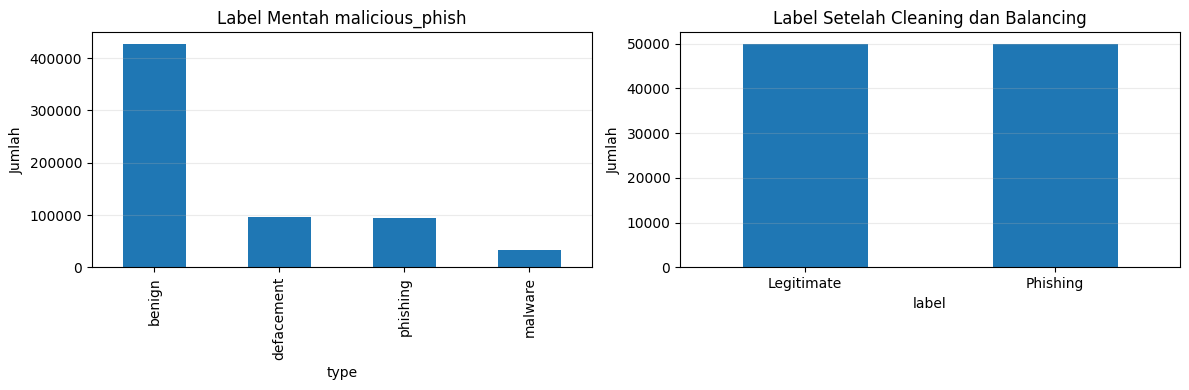

,kelas,baris,url_unik,duplikat_normalized,hostname_unik
0,legitimate,50000,50000,0,50000
1,phishing,50000,50000,0,26142


In [3]:
def normalize_url(value):
    try:
        raw=unicodedata.normalize("NFKC",html.unescape(str(value).strip()))
        parsed=urlsplit(raw if "://" in raw else "https://"+raw)
        hostname=(parsed.hostname or "").lower().rstrip(".")
        if not hostname: return ""
        path=parsed.path or "/"
        return f"{(parsed.scheme or 'https').lower()}://{hostname}{path}" + (
            f"?{parsed.query}" if parsed.query else "")
    except (ValueError,UnicodeError):
        return ""

def hostname_of(value):
    try:
        parsed=urlsplit(value if "://" in value else "https://"+value)
        return (parsed.hostname or "").lower().rstrip(".")
    except (ValueError,UnicodeError):
        return ""

phish_all=pd.read_csv(ROOT/"verified_online.csv",usecols=["url"]).dropna()
phish_all["url"]=phish_all.url.map(normalize_url)
phish_all=phish_all.drop_duplicates("url")
phish_hosts=set(phish_all.url.map(hostname_of))

tranco=pd.read_csv(ROOT/"tranco_6WNKX.csv",header=None,
                   names=["rank","domain"],dtype=str).dropna()
legit_all=pd.DataFrame({"url":("https://"+tranco.domain.str.strip()).map(normalize_url)})
legit_all=legit_all.drop_duplicates("url")
legit_all=legit_all[~legit_all.url.map(hostname_of).isin(phish_hosts)]

real_legit=legit_all.sample(50_000,random_state=SEED).assign(
    label=0,source="tranco_real")
real_phish=phish_all.sample(50_000,random_state=SEED).assign(
    label=1,source="phishtank_real")
real=pd.concat([real_legit,real_phish],ignore_index=True)
real["host"]=real.url.map(hostname_of)
assert real.url.duplicated().sum()==0
assert set(real_legit.url.map(hostname_of)).isdisjoint(
    set(real_phish.url.map(hostname_of)))

# Audit dan cleaning malicious_phish.csv; hanya benign/phishing sesuai target biner.
malicious_raw=pd.read_csv(ROOT/'malicious_phish.csv',dtype={'url':'string','type':'string'})
malicious_audit_before=pd.DataFrame({
 'indikator':['Baris mentah','Missing URL','Missing type','Duplikat URL mentah',
              'Benign','Phishing','Defacement (dikeluarkan)','Malware (dikeluarkan)'],
 'jumlah':[len(malicious_raw),int(malicious_raw.url.isna().sum()),
           int(malicious_raw.type.isna().sum()),int(malicious_raw.url.duplicated().sum()),
           int((malicious_raw.type.str.lower()=='benign').sum()),
           int((malicious_raw.type.str.lower()=='phishing').sum()),
           int((malicious_raw.type.str.lower()=='defacement').sum()),
           int((malicious_raw.type.str.lower()=='malware').sum())]})
malicious=malicious_raw.dropna(subset=['url','type']).copy()
malicious['type']=malicious.type.str.strip().str.lower()
malicious=malicious[malicious.type.isin(['benign','phishing'])].copy()
malicious['url']=malicious.url.map(normalize_url)
malicious['host']=malicious.url.map(hostname_of)
invalid_normalized=int(malicious.host.eq('').sum())
malicious=malicious[malicious.host.ne('')].copy()
malicious['label']=malicious.type.map({'benign':0,'phishing':1}).astype(int)
normalized_duplicates=int(malicious.url.duplicated().sum())
url_label_count=malicious.groupby('url').label.nunique()
conflict_urls=set(url_label_count[url_label_count>1].index)
malicious=malicious[~malicious.url.isin(conflict_urls)].drop_duplicates('url')
host_label_count=malicious.groupby('host').label.nunique()
conflict_hosts=set(host_label_count[host_label_count>1].index)
malicious=malicious[~malicious.host.isin(conflict_hosts)].copy()
base_hosts=set(real.host)
overlap_base_hosts=int(malicious.host.isin(base_hosts).sum())
malicious=malicious[~malicious.host.isin(base_hosts)].copy()
malicious['source']='malicious_phish_real'
external_n=min(50_000,*malicious.groupby('label').size().tolist())
malicious_balanced=pd.concat([malicious[malicious.label==label].sample(
    external_n,random_state=SEED+label) for label in (0,1)],ignore_index=True)
assert malicious_balanced.url.duplicated().sum()==0
assert malicious_balanced.groupby('host').label.nunique().max()==1
display(malicious_audit_before)
display(pd.DataFrame({
 'indikator':['URL malformed/hostname kosong','Duplikat normalized ditemukan','Konflik URL lintas label',
              'Konflik hostname lintas label','Baris overlap sumber utama',
              'Baris bersih tersedia','Baris balanced digunakan'],
 'jumlah':[invalid_normalized,normalized_duplicates,len(conflict_urls),len(conflict_hosts),
           overlap_base_hosts,len(malicious),len(malicious_balanced)]}))
display(malicious_balanced.groupby(['source','label']).agg(
    baris=('url','size'),url_unik=('url','nunique'),hostname_unik=('host','nunique')))
fig,axes=plt.subplots(1,2,figsize=(12,4))
malicious_raw.type.str.lower().value_counts().plot.bar(ax=axes[0],title='Label Mentah malicious_phish')
malicious_balanced.label.value_counts().sort_index().plot.bar(
    ax=axes[1],title='Label Setelah Cleaning dan Balancing')
axes[1].set_xticklabels(['Legitimate','Phishing'],rotation=0)
for ax in axes: ax.set_ylabel('Jumlah'); ax.grid(axis='y',alpha=.25)
plt.tight_layout(); plt.show()

pd.DataFrame({
    "kelas":["legitimate","phishing"],
    "baris":[len(real_legit),len(real_phish)],
    "url_unik":[real_legit.url.nunique(),real_phish.url.nunique()],
    "duplikat_normalized":[real_legit.url.duplicated().sum(),
                            real_phish.url.duplicated().sum()],
    "hostname_unik":[real_legit.url.map(hostname_of).nunique(),
                     real_phish.url.map(hostname_of).nunique()]
})

**Interpretasi:** Tranco dan PhishTank masing-masing tetap menyumbang 50.000 URL nyata. Pada `malicious_phish.csv`, label `defacement` dan `malware` dilaporkan tetapi tidak dipaksa menjadi phishing karena target penelitian adalah phishing biner. Hanya `benign` dan `phishing` yang dinormalisasi; URL kosong, duplikasi, konflik label pada URL/hostname, serta overlap hostname dengan sumber utama dibuang. Setelah cleaning diambil 50.000 data per kelas secara seimbang. Sumber baru menambah variasi nyata tanpa class imbalance atau leakage antar-sumber.

## 5. Memuat dan memvalidasi data sintetis

In [4]:
synth_legit = pd.read_csv(ROOT/'synthetic_legitimate_50000.csv')
synth_phish = pd.read_csv(ROOT/'synthetic_phishing_50000.csv')
synthetic = pd.concat([synth_legit, synth_phish], ignore_index=True)
synthetic['label'] = synthetic['label'].map({'legitimate':0, 'phishing':1})

audit_sintetis = pd.DataFrame({
    'baris': [len(synth_legit), len(synth_phish)],
    'url_unik': [synth_legit.url.nunique(), synth_phish.url.nunique()],
    'duplikat': [synth_legit.duplicated('url').sum(), synth_phish.duplicated('url').sum()],
    'missing': [synth_legit.isna().sum().sum(), synth_phish.isna().sum().sum()]
}, index=['legitimate','phishing'])
audit_sintetis

,baris,url_unik,duplikat,missing
legitimate,50000,50000,0,0
phishing,50000,50000,0,0


**Interpretasi:** kedua kelas harus menunjukkan 50.000 baris, 50.000 URL unik, nol duplikat, dan nol missing value. Sintetis legitimate dibuat sebagai IDN native/non-homograph; sintetis phishing dibuat sebagai mutasi visual domain beragam. Ini memperbaiki dataset lama yang keliru melabeli homograph merek sebagai legitimate.

## 6. EDA dan pemeriksaan kualitas gabungan

,dimensi,indikator,hasil
0,Kelengkapan,Missing URL/label,0
1,Keunikan,Duplicate normalized URL,0
2,Konsistensi,Label di luar 0/1,0
3,Validitas,Hostname kosong,0
4,Integritas,Konflik hostname lintas label,0


source                label
malicious_phish_real  0        50000
                      1        50000
phishtank_real        1        50000
synthetic_homograph   1        50000
synthetic_native_idn  0        50000
tranco_real           0        50000
Name: jumlah, dtype: int64

url_length                                               host_length  \
           count   mean    std   min   25%   50%   75%     max       count   
label                                                                        
0       150000.0  43.08  30.39  13.0  25.0  39.0  46.0  1068.0    150000.0   
1       150000.0  55.10  44.26  11.0  34.0  49.0  63.0  3590.0    150000.0   

              ... digit_count        special_count                             \
        mean  ...         75%    max         count  mean   std  min  25%  50%   
label         ...                                                               
0      19.92  ...        10.0  554.0      150000.0  8.07  4.80  5.0  5.0  8.0   
1      22.58  ...         3.0  738.0      150000.0  9.58  4.63  4.0  7.0  9.0   

                    
        75%    max  
label               
0       8.0  159.0  
1      12.0  188.0  

[2 rows x 56 columns]

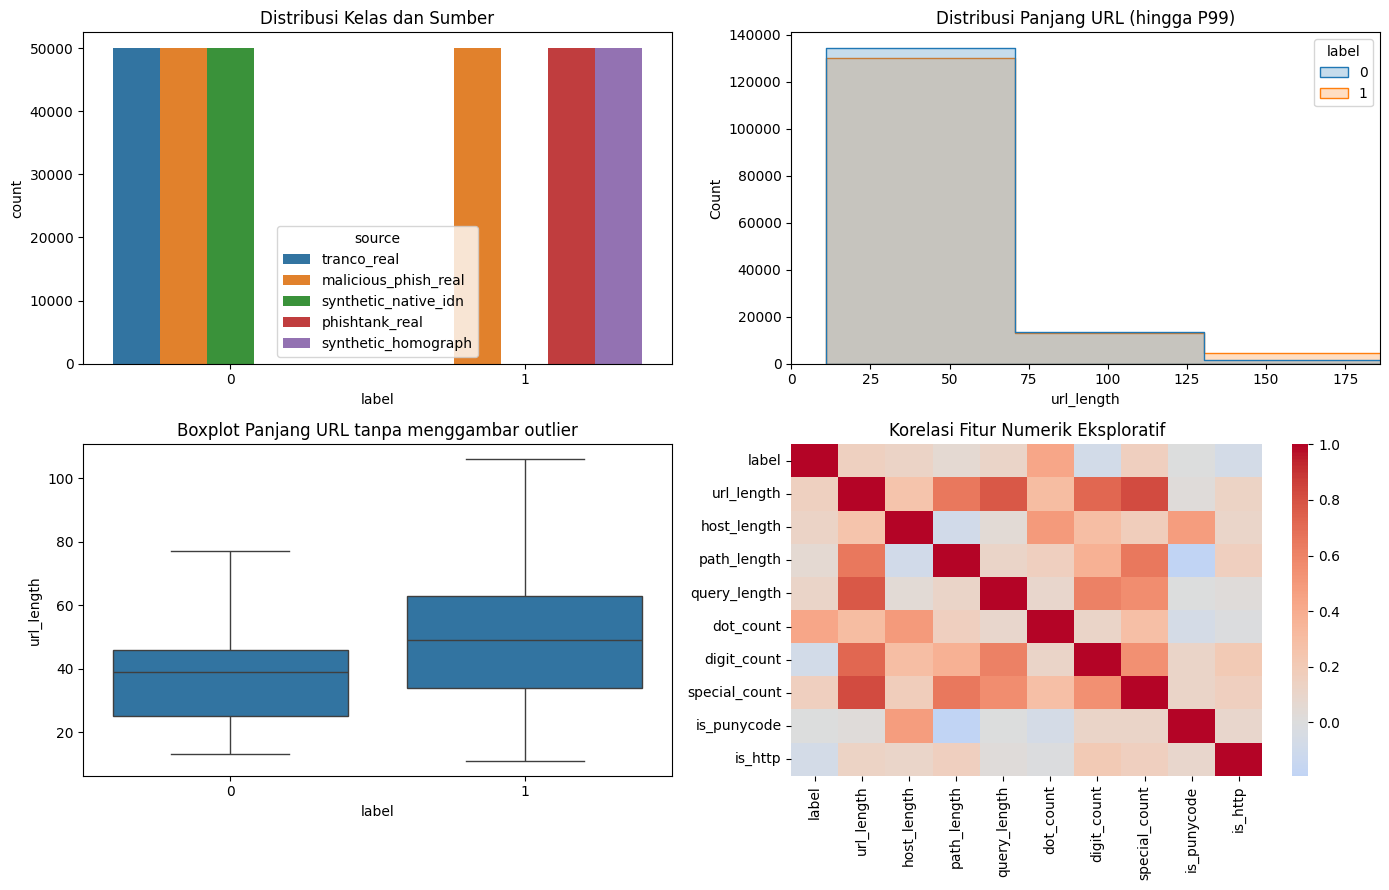

Batas IQR panjang URL: 101.5 | jumlah outlier: 14725


In [5]:
combined=pd.concat([real[["url","label","source"]],
                    malicious_balanced[["url","label","source"]],
                    synthetic[["url","label","source"]]],ignore_index=True)
parsed=combined.url.map(lambda value:urlsplit(value if "://" in value else "https://"+value))
combined["url_length"]=combined.url.str.len()
combined["host_length"]=parsed.map(lambda p:len(p.hostname or ""))
combined["path_length"]=parsed.map(lambda p:len(p.path or ""))
combined["query_length"]=parsed.map(lambda p:len(p.query or ""))
combined["dot_count"]=parsed.map(lambda p:(p.hostname or "").count("."))
combined["digit_count"]=combined.url.map(lambda x:sum(ch.isdigit() for ch in x))
combined["special_count"]=combined.url.map(lambda x:sum(not ch.isalnum() for ch in x))
combined["is_punycode"]=combined.url.str.contains("xn--",regex=False).astype(int)
combined["is_http"]=combined.url.str.startswith("http://").astype(int)

quality_summary=pd.DataFrame({
 "dimensi":["Kelengkapan","Keunikan","Konsistensi","Validitas","Integritas"],
 "indikator":["Missing URL/label","Duplicate normalized URL","Label di luar 0/1",
              "Hostname kosong","Konflik hostname lintas label"],
 "hasil":[int(combined[["url","label"]].isna().sum().sum()),
          int(combined.url.duplicated().sum()),
          int((~combined.label.isin([0,1])).sum()),
          int(parsed.map(lambda p:not bool(p.hostname)).sum()),
          int(len(set(real[real.label==0].host)&set(real[real.label==1].host)))]})
display(quality_summary)
display(combined.groupby(["source","label"]).size().rename("jumlah"))
display(combined.groupby("label")[["url_length","host_length","path_length",
    "query_length","dot_count","digit_count","special_count"]].describe().round(2))

fig,axes=plt.subplots(2,2,figsize=(14,9))
sns.countplot(data=combined,x="label",hue="source",ax=axes[0,0]);axes[0,0].set_title("Distribusi Kelas dan Sumber")
sns.histplot(data=combined,x="url_length",hue="label",bins=60,element="step",ax=axes[0,1]);axes[0,1].set_xlim(0,combined.url_length.quantile(.99));axes[0,1].set_title("Distribusi Panjang URL (hingga P99)")
sns.boxplot(data=combined,x="label",y="url_length",showfliers=False,ax=axes[1,0]);axes[1,0].set_title("Boxplot Panjang URL tanpa menggambar outlier")
corr_cols=["label","url_length","host_length","path_length","query_length",
           "dot_count","digit_count","special_count","is_punycode","is_http"]
sns.heatmap(combined[corr_cols].corr(),cmap="coolwarm",center=0,ax=axes[1,1]);axes[1,1].set_title("Korelasi Fitur Numerik Eksploratif")
plt.tight_layout();plt.show()

q1,q3=combined.url_length.quantile([.25,.75]);iqr=q3-q1
upper=q3+1.5*iqr
print("Batas IQR panjang URL:",round(upper,2),"| jumlah outlier:",int((combined.url_length>upper).sum()))

**Interpretasi:** matriks kualitas menguji kelengkapan, keunikan, konsistensi label, validitas hostname, dan integritas label lintas sumber. Korelasi bersifat EDA, bukan dasar kausal. Outlier panjang URL dihitung tetapi tidak otomatis dibuang karena URL panjang dapat merupakan sinyal serangan; menghapusnya justru dapat menghilangkan pola target. Plot dibatasi pada persentil ke-99 hanya agar visual terbaca.

## 7. Split real berbasis kelompok hostname

In [6]:
# Holdout utama tetap Tranco/PhishTank dan tidak disentuh sumber eksternal.
train_parts,test_parts=[],[]
for label in (0,1):
    part=real[real.label==label]
    splitter=GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEED)
    i_train,i_test=next(splitter.split(part,groups=part.host))
    train_parts.append(part.iloc[i_train]); test_parts.append(part.iloc[i_test])
n_train=min(map(len,train_parts)); n_test=min(map(len,test_parts))
real_train_base=pd.concat([x.sample(n_train,random_state=SEED) for x in train_parts])
real_test=pd.concat([x.sample(n_test,random_state=SEED) for x in test_parts])
assert set(real_train_base.host).isdisjoint(set(real_test.host))

# Split sumber external berbasis hostname sebelum masuk training.
external_train_parts,external_test_parts=[],[]
for label in (0,1):
    part=malicious_balanced[malicious_balanced.label==label]
    splitter=GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEED+21)
    i_train,i_test=next(splitter.split(part,groups=part.host))
    external_train_parts.append(part.iloc[i_train])
    external_test_parts.append(part.iloc[i_test])
external_train_n=min(map(len,external_train_parts))
external_test_n=min(map(len,external_test_parts))
external_train=pd.concat([x.sample(external_train_n,random_state=SEED)
                          for x in external_train_parts])
external_test=pd.concat([x.sample(external_test_n,random_state=SEED)
                         for x in external_test_parts])
assert set(external_train.host).isdisjoint(set(external_test.host))
assert set(external_train.host).isdisjoint(set(real_test.host))

# Augmentasi konservatif: sumber external tidak boleh mendominasi distribusi utama.
EXTERNAL_RATIO=.10
external_phishing_pool=external_train[external_train.label==1]
external_each=max(1,int(len(external_phishing_pool)*EXTERNAL_RATIO))
external_phishing_selected=external_phishing_pool.sample(
    external_each,random_state=SEED+101)
# Pasangan legitimate berasal dari Tranco tambahan; benign external tetap challenge-set.
excluded_hosts=set(real.host)|set(malicious_balanced.host)
extra_legitimate_candidates=legit_all[
    ~legit_all.url.map(hostname_of).isin(excluded_hosts)].copy()
extra_legitimate=extra_legitimate_candidates.sample(
    external_each,random_state=SEED+102).assign(label=0,source='tranco_external_match')
extra_legitimate['host']=extra_legitimate.url.map(hostname_of)
external_operational=pd.concat([extra_legitimate,external_phishing_selected],ignore_index=True)
real_train=pd.concat([real_train_base,external_operational],ignore_index=True).sample(
    frac=1,random_state=SEED)
assert real_train.label.value_counts().nunique()==1
display(pd.DataFrame({
 'subset':['real_train_base','external_pool','external_dipakai_10%','real_train_total','real_test_utama','external_test'],
 'baris':[len(real_train_base),len(external_train),len(external_operational),len(real_train),len(real_test),len(external_test)],
 'legitimate':[int((real_train_base.label==0).sum()),int((external_train.label==0).sum()),int((external_operational.label==0).sum()),
               int((real_train.label==0).sum()),int((real_test.label==0).sum()),
               int((external_test.label==0).sum())],
 'phishing':[int((real_train_base.label==1).sum()),int((external_train.label==1).sum()),int((external_operational.label==1).sum()),
             int((real_train.label==1).sum()),int((real_test.label==1).sum()),
             int((external_test.label==1).sum())]}))

,subset,baris,legitimate,phishing
0,real_train_base,80000,40000,40000
1,external_pool,76484,38242,38242
2,external_dipakai_10%,7648,3824,3824
3,real_train_total,87648,43824,43824
4,real_test_utama,12874,6437,6437
5,external_test,19596,9798,9798


**Interpretasi:** seluruh pemisahan memakai hostname sebagai group, sehingga dua URL dari host yang sama tidak tersebar ke train dan test. Holdout utama Tranco/PhishTank tetap tidak disentuh saat tuning. `malicious_phish` mempunyai train dan external-test sendiri; hanya bagian train yang digabungkan ke real training. Semua subset diseimbangkan per kelas, dan assertion membuktikan tidak ada overlap hostname dengan holdout utama.

## 8. Feature engineering: URL dan indikator phishing

In [7]:
SUSPICIOUS = {'login','signin','verify','verification','secure','account',
              'update','password','wallet','invoice','suspended','confirm'}

def prepare_url(value):
    raw = unicodedata.normalize('NFKC', html.unescape(str(value).strip())).lower()
    parsed = urlsplit(raw if '://' in raw else 'https://'+raw)
    host, pq, tokens = (parsed.hostname or '').rstrip('.'), f'{parsed.path}?{parsed.query}', []
    try:
        ipaddress.ip_address(host.strip('[]')); tokens.append('__host_ip__')
    except ValueError: pass
    if '@' in parsed.netloc: tokens.append('__at_symbol__')
    if host.count('.') >= 3: tokens.append('__many_subdomains__')
    if len(raw) >= 75: tokens.append('__long_url__')
    if host.startswith('xn--') or '.xn--' in host: tokens.append('__punycode__')
    if parsed.scheme == 'http': tokens.append('__plain_http__')
    if any(word in pq for word in SUSPICIOUS): tokens.append('__suspicious_path__')
    if re.search(r'%[0-9a-f]{2}', raw): tokens.append('__percent_encoding__')
    return raw + ' ' + ' '.join(tokens)

for sample in ['http://192.0.2.1/login?account=verify',
               'https://example.com/about', 'xn--gogle-jye.com']:
    print(prepare_url(sample))

http://192.0.2.1/login?account=verify __host_ip__ __many_subdomains__ __plain_http__ __suspicious_path__
https://example.com/about 
xn--gogle-jye.com __punycode__


**Interpretasi:** indikator tidak langsung memvonis phishing; indikator menjadi token tambahan yang dipelajari bersama character n-gram. NFKC menangani bentuk fullwidth, sedangkan `xn--` memberi sinyal Punycode tanpa menganggap seluruh Punycode berbahaya.

## 9. Vectorization dan training

In [8]:
# Split sintetis berbasis hostname sebelum tuning/training.
synthetic["host"]=synthetic.url.map(hostname_of)
synth_train_parts,synth_test_parts=[],[]
for label in (0,1):
    part=synthetic[synthetic.label==label]
    splitter=GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEED)
    a,b=next(splitter.split(part,groups=part.host))
    synth_train_parts.append(part.iloc[a]); synth_test_parts.append(part.iloc[b])
synth_train_n=min(map(len,synth_train_parts)); synth_test_n=min(map(len,synth_test_parts))
synth_train=pd.concat([x.sample(synth_train_n,random_state=SEED) for x in synth_train_parts]).sample(frac=1,random_state=SEED)
synth_test=pd.concat([x.sample(synth_test_n,random_state=SEED) for x in synth_test_parts]).sample(frac=1,random_state=SEED)
assert set(synth_train.host).isdisjoint(set(synth_test.host))

# Mitigasi overfitting: konfigurasi dipilih pada validation nyata, bukan final test.
tune_train_parts,tune_val_parts=[],[]
for label in (0,1):
    part=real_train_base[real_train_base.label==label]
    splitter=GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEED+7)
    a,b=next(splitter.split(part,groups=part.host))
    tune_train_parts.append(part.iloc[a]); tune_val_parts.append(part.iloc[b])
tn=min(map(len,tune_train_parts)); vn=min(map(len,tune_val_parts))
tune_real=pd.concat([x.sample(tn,random_state=SEED) for x in tune_train_parts])
tune_val=pd.concat([x.sample(vn,random_state=SEED) for x in tune_val_parts])

tune_real_augmented=pd.concat([tune_real[["url","label"]],
    external_operational[["url","label"]]],ignore_index=True)
tune_pool=pd.concat([tune_real_augmented,synth_train[["url","label"]]],ignore_index=True)
tune_vectorizer=TfidfVectorizer(analyzer="char",ngram_range=(3,5),min_df=3,
    max_features=120_000,sublinear_tf=True,dtype=np.float32)
X_tune=tune_vectorizer.fit_transform(tune_pool.url.map(prepare_url))
X_val=tune_vectorizer.transform(tune_val.url.map(prepare_url))
tuning=[]; real_n=len(tune_real_augmented)
for ratio in [.25,.50]:
    per_class=int(min(synth_train.label.value_counts())*ratio); chosen=[]
    for label in (0,1):
        available=np.flatnonzero(synth_train.label.to_numpy()==label)
        if per_class:
            chosen.extend(np.random.default_rng(SEED+int(ratio*100)+label).choice(
                available,per_class,replace=False))
    use=np.r_[np.arange(real_n),real_n+np.asarray(chosen,dtype=int)]
    for alpha in [.05,.1,.2,.5,1.0]:
        candidate=MultinomialNB(alpha=alpha).fit(X_tune[use],tune_pool.label.iloc[use])
        train_f1=precision_recall_fscore_support(tune_pool.label.iloc[use],candidate.predict(X_tune[use]),average="binary")[2]
        val_prediction=candidate.predict(X_val)
        val_precision,val_recall,val_f1,_=precision_recall_fscore_support(tune_val.label,val_prediction,average="binary")
        gap=train_f1-val_f1
        score=.5*val_f1+.5*val_recall-.50*max(gap,0)
        tuning.append({"synthetic_ratio":ratio,"alpha":alpha,"train_f1":train_f1,
                       "validation_f1":val_f1,"validation_recall":val_recall,
                       "gap":gap,"selection_score":score})
tuning_results=pd.DataFrame(tuning).sort_values(["selection_score","validation_f1"],ascending=False)
display(tuning_results.head(10).style.format({
    "synthetic_ratio":"{:.0%}","train_f1":"{:.2%}","validation_f1":"{:.2%}",
    "validation_recall":"{:.2%}","gap":"{:.2%}","selection_score":"{:.4f}"}))
selected=tuning_results.iloc[0]
SELECTED_RATIO=float(selected.synthetic_ratio); SELECTED_ALPHA=float(selected.alpha)

# Threshold dipilih hanya dari validation nyata; final test tidak disentuh.
selected_per_class=int(min(synth_train.label.value_counts())*SELECTED_RATIO)
selected_tune_rows=[]
for label in (0,1):
    available=np.flatnonzero(synth_train.label.to_numpy()==label)
    if selected_per_class:
        selected_tune_rows.extend(np.random.default_rng(
            SEED+int(SELECTED_RATIO*100)+label).choice(
                available,selected_per_class,replace=False))
selected_use=np.r_[np.arange(real_n),real_n+np.asarray(selected_tune_rows,dtype=int)]
threshold_model=MultinomialNB(alpha=SELECTED_ALPHA).fit(
    X_tune[selected_use],tune_pool.label.iloc[selected_use])
validation_probability=threshold_model.predict_proba(X_val)[:,1]
threshold_rows=[]
for threshold in np.linspace(.20,.80,61):
    prediction=(validation_probability>=threshold).astype(int)
    precision,recall,f1,_=precision_recall_fscore_support(
        tune_val.label,prediction,average="binary",zero_division=0)
    feasible=precision>=.94
    score=f1+.10*recall if feasible else -1
    threshold_rows.append({"threshold":threshold,"precision":precision,
        "recall":recall,"f1":f1,"feasible":feasible,"selection_score":score})
threshold_results=pd.DataFrame(threshold_rows)
threshold_best=threshold_results.sort_values(
    ["selection_score","f1"],ascending=False).iloc[0]
SELECTED_THRESHOLD=float(threshold_best.threshold)
display(threshold_results.sort_values("selection_score",ascending=False).head(10)
        .style.format({"threshold":"{:.2f}","precision":"{:.2%}",
                       "recall":"{:.2%}","f1":"{:.2%}",
                       "selection_score":"{:.4f}"}))
print("Threshold validation terpilih:",SELECTED_THRESHOLD)

# Ambil synthetic-train secara seimbang sesuai hasil validation.
selected_n=int(min(synth_train.label.value_counts())*SELECTED_RATIO); selected_rows=[]
for label in (0,1):
    available=np.flatnonzero(synth_train.label.to_numpy()==label)
    if selected_n:
        selected_rows.extend(np.random.default_rng(SEED+900+label).choice(
            available,selected_n,replace=False))
synth_operational=synth_train.iloc[selected_rows]
train=pd.concat([real_train[["url","label"]],synth_operational[["url","label"]]],ignore_index=True).sample(frac=1,random_state=SEED)
mixed_test=pd.concat([real_test[["url","label"]],synth_test[["url","label"]]],ignore_index=True).sample(frac=1,random_state=SEED)

vectorizer=TfidfVectorizer(analyzer="char",ngram_range=(3,5),min_df=3,
    max_features=120_000,sublinear_tf=True,dtype=np.float32)
X_train=vectorizer.fit_transform(train.url.map(prepare_url))
X_test=vectorizer.transform(real_test.url.map(prepare_url))
X_mixed=vectorizer.transform(mixed_test.url.map(prepare_url))
X_external=vectorizer.transform(external_test.url.map(prepare_url))
print("Terpilih:",SELECTED_RATIO,SELECTED_ALPHA)
print("Training real+sintetis teratur:",X_train.shape)
display(train.label.value_counts().rename("train"))

,synthetic_ratio,alpha,train_f1,validation_f1,validation_recall,gap,selection_score
5,50%,0.050000,97.81%,94.91%,92.67%,2.90%,0.9234
0,25%,0.050000,97.39%,94.92%,91.93%,2.47%,0.9219
6,50%,0.100000,97.70%,94.58%,91.78%,3.12%,0.9162
1,25%,0.100000,97.22%,94.52%,91.02%,2.70%,0.9142
7,50%,0.200000,97.52%,94.19%,90.89%,3.33%,0.9088
2,25%,0.200000,96.97%,93.98%,89.83%,2.99%,0.9041
8,50%,0.500000,97.22%,93.21%,88.96%,4.01%,0.8908
3,25%,0.500000,96.60%,92.87%,87.64%,3.73%,0.8839
9,50%,1.000000,96.94%,92.24%,87.08%,4.70%,0.8730
4,25%,1.000000,96.28%,92.03%,86.14%,4.25%,0.8696


,threshold,precision,recall,f1,feasible,selection_score
28,0.48,97.14%,92.87%,94.96%,True,1.0424
18,0.38,96.23%,93.54%,94.87%,True,1.0422
27,0.47,97.03%,92.91%,94.93%,True,1.0422
29,0.49,97.18%,92.78%,94.93%,True,1.0421
17,0.37,96.13%,93.60%,94.85%,True,1.0421
26,0.46,96.93%,92.97%,94.91%,True,1.0421
10,0.30,95.31%,94.25%,94.78%,True,1.0420
24,0.44,96.78%,93.08%,94.89%,True,1.0420
16,0.36,96.02%,93.67%,94.83%,True,1.0420
25,0.45,96.84%,93.02%,94.89%,True,1.0419


Threshold validation terpilih: 0.48000000000000004


Terpilih: 0.5 0.05
Training real+sintetis teratur: (127646, 120000)


label
0    63823
1    63823
Name: train, dtype: int64

**Interpretasi hasil tuning:** validation nyata memilih 50% synthetic-train dan alpha 0.05 setelah hard phishing examples dari `malicious_phish` ditambahkan secara konservatif. Dataset external tidak dibiarkan mendominasi training. Threshold keputusan dipilih pada validation Tranco/PhishTank hostname-disjoint dengan precision minimum 94%; final test tidak digunakan dalam pemilihan parameter atau threshold.

In [9]:
models={
 "MultinomialNB":MultinomialNB(alpha=SELECTED_ALPHA),
 "ComplementNB":ComplementNB(alpha=SELECTED_ALPHA),
 "BernoulliNB":BernoulliNB(alpha=.05,binarize=.0)}
def metric_set(y,probability,threshold=.5):
    prediction=(probability>=threshold).astype(int)
    precision,recall,f1,_=precision_recall_fscore_support(
        y,prediction,average="binary",zero_division=0)
    tn,fp,fn,tp=confusion_matrix(y,prediction).ravel()
    return {"accuracy":accuracy_score(y,prediction),"precision":precision,
      "recall":recall,"f1":f1,"roc_auc":roc_auc_score(y,probability),
      "pr_auc":average_precision_score(y,probability),"tn":int(tn),
      "fp":int(fp),"fn":int(fn),"tp":int(tp),"test_size":len(y)}
results_real,results_external,results_mixed,fitted={},{},{},{}
for name,model in models.items():
    model.fit(X_train,train.label)
    results_real[name]=metric_set(real_test.label.to_numpy(),
                                   model.predict_proba(X_test)[:,1])
    results_external[name]=metric_set(external_test.label.to_numpy(),
                                       model.predict_proba(X_external)[:,1])
    results_mixed[name]=metric_set(mixed_test.label.to_numpy(),
                                    model.predict_proba(X_mixed)[:,1])
    fitted[name]=model
# Hanya model operasional memakai threshold hasil validation.
results_real["MultinomialNB"]=metric_set(real_test.label.to_numpy(),
    fitted["MultinomialNB"].predict_proba(X_test)[:,1],SELECTED_THRESHOLD)
results_external["MultinomialNB"]=metric_set(external_test.label.to_numpy(),
    fitted["MultinomialNB"].predict_proba(X_external)[:,1],SELECTED_THRESHOLD)
results_mixed["MultinomialNB"]=metric_set(mixed_test.label.to_numpy(),
    fitted["MultinomialNB"].predict_proba(X_mixed)[:,1],SELECTED_THRESHOLD)
display(pd.DataFrame(results_real).T.style.format(
    {k:"{:.2%}" for k in ["accuracy","precision","recall","f1","roc_auc","pr_auc"]}))
print('External real test — malicious_phish.csv')
display(pd.DataFrame(results_external).T.style.format(
    {k:"{:.2%}" for k in ["accuracy","precision","recall","f1","roc_auc","pr_auc"]}))
print('Mixed test')
display(pd.DataFrame(results_mixed).T.style.format(
    {k:"{:.2%}" for k in ["accuracy","precision","recall","f1","roc_auc","pr_auc"]}))

,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,test_size
MultinomialNB,95.45%,97.36%,93.43%,95.35%,98.39%,98.79%,6274.000000,163.000000,423.000000,6014.000000,12874.000000
ComplementNB,95.39%,97.39%,93.29%,95.29%,98.39%,98.79%,6276.000000,161.000000,432.000000,6005.000000,12874.000000
BernoulliNB,92.43%,99.80%,85.02%,91.82%,98.30%,98.70%,6426.000000,11.000000,964.000000,5473.000000,12874.000000


External real test — malicious_phish.csv


,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,test_size
MultinomialNB,56.18%,54.19%,79.91%,64.59%,53.95%,51.96%,3179.000000,6619.000000,1968.000000,7830.000000,19596.000000
ComplementNB,56.37%,54.34%,79.82%,64.66%,53.95%,51.95%,3226.000000,6572.000000,1977.000000,7821.000000,19596.000000
BernoulliNB,45.94%,46.80%,59.29%,52.31%,47.27%,48.40%,3194.000000,6604.000000,3989.000000,5809.000000,19596.000000


Mixed test


,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,test_size
MultinomialNB,98.22%,98.99%,97.43%,98.20%,99.75%,99.78%,16274.000000,163.000000,423.000000,16014.000000,32874.000000
ComplementNB,98.20%,99.00%,97.37%,98.18%,99.75%,99.78%,16276.000000,161.000000,432.000000,16005.000000,32874.000000
BernoulliNB,97.03%,99.93%,94.14%,96.95%,99.72%,99.73%,16426.000000,11.000000,964.000000,15473.000000,32874.000000


**Interpretasi:** model dipilih berdasarkan F1 lalu recall, bukan accuracy saja. Recall penting karena false negative berarti URL phishing lolos sebagai aman; precision tetap dijaga agar legitimate tidak terlalu sering diblokir.

## 10. Seluruh Model Naive Bayes dan Kecocokan Asumsi

| Model | Feature track | Transformasi | Kesesuaian |
|---|---|---|---|
| MultinomialNB | Character TF-IDF | Non-negatif, sparse | Kandidat utama untuk frekuensi/bobot n-gram |
| ComplementNB | Character TF-IDF | Non-negatif, sparse | Menggunakan statistik kelas komplemen |
| BernoulliNB | Kehadiran n-gram | Binarisasi pada nol | Cocok bila presence lebih penting dari bobot |
| GaussianNB | 15 fitur kontinu | StandardScaler | Memerlukan pendekatan distribusi Gaussian |
| CategoricalNB | 15 fitur diskret | Quantile binning | Memerlukan kategori integer non-negatif |

GaussianNB dan CategoricalNB tidak dipaksa menerima TF-IDF sparse. Membandingkan model dengan feature track yang sesuai lebih benar daripada sekadar memberikan matriks identik kepada semua algoritma. Model dipilih melalui validation nyata; final test hanya digunakan setelah konfigurasi dikunci.

In [10]:
# Jalur fitur numerik untuk GaussianNB dan CategoricalNB.
import math
from collections import Counter
from sklearn.preprocessing import KBinsDiscretizer, StandardScaler
from sklearn.naive_bayes import GaussianNB, CategoricalNB

NUMERIC_WORDS = ("login","signin","verify","secure","account","update",
                 "password","wallet","invoice")
def numeric_url_features(value):
    raw=str(value).lower()
    parsed=urlsplit(raw if "://" in raw else "https://"+raw)
    host=parsed.hostname or ""; path=parsed.path or ""; query=parsed.query or ""
    counts=Counter(raw); n=max(len(raw),1)
    entropy=-sum((count/n)*math.log2(count/n) for count in counts.values())
    return [len(raw),len(host),len(path),len(query),host.count("."),
            host.count("-"),sum(c.isdigit() for c in raw),
            sum(not c.isalnum() for c in raw),entropy,int("xn--" in host),
            int("@" in parsed.netloc),int(parsed.scheme=="http"),
            int(any(w in path+"?"+query for w in NUMERIC_WORDS)),
            int("%" in raw),max(host.count(".")-1,0)]

X_num=np.asarray([numeric_url_features(x) for x in train.url],dtype=float)
Xt_num=np.asarray([numeric_url_features(x) for x in real_test.url],dtype=float)
Xm_num=np.asarray([numeric_url_features(x) for x in mixed_test.url],dtype=float)

scaler=StandardScaler()
X_gauss=scaler.fit_transform(X_num); Xt_gauss=scaler.transform(Xt_num); Xm_gauss=scaler.transform(Xm_num)
gaussian=GaussianNB(var_smoothing=1e-9).fit(X_gauss,train.label)

binner=KBinsDiscretizer(n_bins=10,encode="ordinal",strategy="quantile",
                        quantile_method="averaged_inverted_cdf")
X_cat=binner.fit_transform(X_num).astype(int)
Xt_cat=binner.transform(Xt_num).astype(int)
Xm_cat=binner.transform(Xm_num).astype(int)
categorical=CategoricalNB(alpha=1.0).fit(X_cat,train.label)

def evaluate_probability(name, probability):
    prediction=(probability>=.5).astype(int)
    precision,recall,f1,_=precision_recall_fscore_support(
        real_test.label,prediction,average="binary")
    return {"accuracy":accuracy_score(real_test.label,prediction),
            "precision":precision,"recall":recall,"f1":f1,
            "roc_auc":roc_auc_score(real_test.label,probability),
            "pr_auc":average_precision_score(real_test.label,probability)}

numeric_results={
    "GaussianNB":evaluate_probability(
        "GaussianNB",gaussian.predict_proba(Xt_gauss)[:,1]),
    "CategoricalNB":evaluate_probability(
        "CategoricalNB",categorical.predict_proba(Xt_cat)[:,1])
}
# Calculate mixed-test metrics with mixed-test labels.
numeric_mixed={
    "GaussianNB":metric_set(mixed_test.label.to_numpy(),
                            gaussian.predict_proba(Xm_gauss)[:,1]),
    "CategoricalNB":metric_set(mixed_test.label.to_numpy(),
                               categorical.predict_proba(Xm_cat)[:,1])
}
results_real.update({k:metric_set(real_test.label.to_numpy(),
    (gaussian.predict_proba(Xt_gauss)[:,1] if k=="GaussianNB"
     else categorical.predict_proba(Xt_cat)[:,1])) for k in numeric_results})
results_mixed.update(numeric_mixed)
display(pd.DataFrame(numeric_results).T.style.format("{:.2%}"))
display(pd.DataFrame(numeric_mixed).T.style.format(
    {k:"{:.2%}" for k in ["accuracy","precision","recall","f1","roc_auc","pr_auc"]}))

D:\Gumelar Akhirul\PYTHON\Lib\site-packages\sklearn\preprocessing\_discretization.py:396: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\Gumelar Akhirul\PYTHON\Lib\site-packages\sklearn\preprocessing\_discretization.py:396: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 3 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\Gumelar Akhirul\PYTHON\Lib\site-packages\sklearn\preprocessing\_discretization.py:396: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\Gumelar Akhirul\PYTHON\Lib\site-packages\sklearn\preprocessing\_discretization.py:396: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 5 are removed. Consider decreasing the number of bins.
  warnings.warn(
D:\Gumelar Akhirul\PYTHON\Lib\site-packages\sklearn\preprocessing\_d

,accuracy,precision,recall,f1,roc_auc,pr_auc
GaussianNB,64.15%,99.46%,28.46%,44.26%,95.50%,96.47%
CategoricalNB,91.45%,92.39%,90.34%,91.35%,96.74%,97.35%


,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,test_size
GaussianNB,85.96%,99.92%,71.98%,83.68%,97.41%,98.32%,16427.000000,10.000000,4605.000000,11832.000000,32874.000000
CategoricalNB,95.76%,95.64%,95.89%,95.76%,98.17%,98.76%,15719.000000,718.000000,676.000000,15761.000000,32874.000000


**Interpretasi:** GaussianNB tidak boleh langsung menerima matriks TF-IDF sparse karena asumsinya adalah fitur kontinu berdistribusi Gaussian. CategoricalNB juga membutuhkan kategori diskret. Karena itu keduanya dibandingkan melalui 15 fitur leksikal numerik yang sesuai, dengan standardisasi untuk GaussianNB dan quantile binning untuk CategoricalNB. Perbandingan ini lebih adil daripada memaksa satu representasi fitur ke semua varian.

## 11. Hasil eksperimen final

### Evaluasi primer: test nyata bebas leakage

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---:|---:|---:|---:|---:|---:|
| MultinomialNB | 95.45% | 97.36% | 93.43% | 95.35% | 98.39% | 98.79% |
| ComplementNB | 95.39% | 97.39% | 93.29% | 95.29% | 98.39% | 98.79% |
| BernoulliNB | 92.43% | 99.80% | 85.02% | 91.82% | 98.30% | 98.70% |
| GaussianNB | 64.15% | 99.46% | 28.46% | 44.26% | 95.50% | 96.47% |
| CategoricalNB | 91.45% | 92.39% | 90.34% | 91.35% | 96.74% | 97.35% |

### Evaluasi sekunder: test gabungan nyata + sintetis

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---:|---:|---:|---:|---:|---:|
| MultinomialNB | 98.22% | 98.99% | 97.43% | 98.20% | 99.75% | 99.78% |
| ComplementNB | 98.20% | 99.00% | 97.37% | 98.18% | 99.75% | 99.78% |
| BernoulliNB | 97.03% | 99.93% | 94.14% | 96.95% | 99.72% | 99.73% |
| GaussianNB | 85.96% | 99.92% | 71.98% | 83.68% | 97.41% | 98.32% |
| CategoricalNB | 95.76% | 95.64% | 95.89% | 95.76% | 98.17% | 98.76% |

**Model terpilih: MultinomialNB.** Pada external challenge set, F1 hanya 64.59% dan ROC-AUC 53.95%; ini menunjukkan domain shift dan kelemahan label historis `malicious_phish`, sehingga hasil external tidak boleh disamakan dengan holdout utama. Data baru dipakai secara konservatif sebagai hard phishing examples, bukan sebagai pengganti sumber berlabel lebih kuat.

## 12. Confusion matrix dan kurva evaluasi

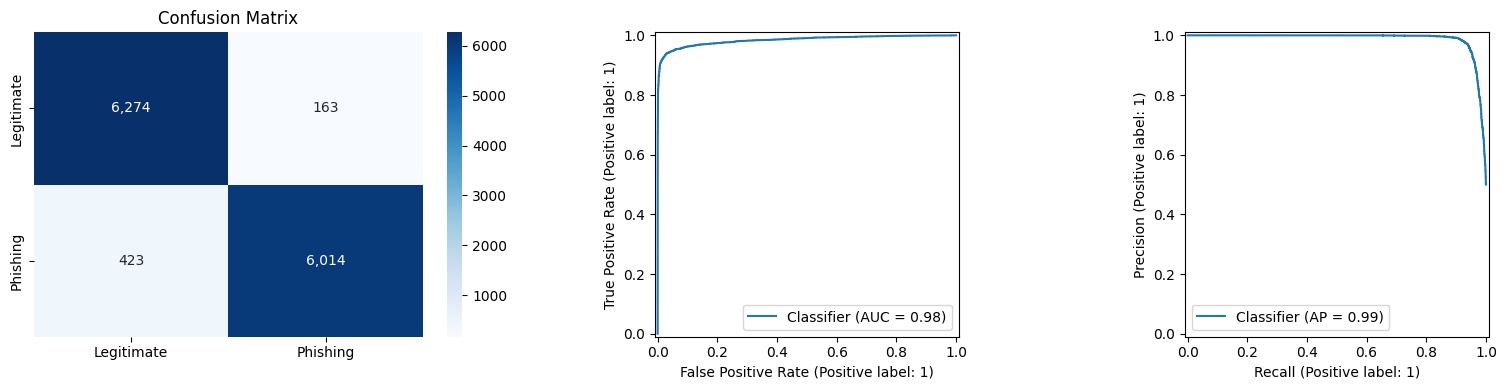

              precision    recall  f1-score   support

  legitimate       0.94      0.97      0.96      6437
    phishing       0.97      0.93      0.95      6437

    accuracy                           0.95     12874
   macro avg       0.96      0.95      0.95     12874
weighted avg       0.96      0.95      0.95     12874



In [11]:
best = models['MultinomialNB']
best_proba = best.predict_proba(X_test)[:,1]
best_pred = (best_proba >= SELECTED_THRESHOLD).astype(int)
cm = confusion_matrix(real_test.label, best_pred)
fig, axes = plt.subplots(1,3,figsize=(16,4))
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', ax=axes[0],
            xticklabels=['Legitimate','Phishing'], yticklabels=['Legitimate','Phishing'])
axes[0].set_title('Confusion Matrix')
RocCurveDisplay.from_predictions(real_test.label,best_proba,ax=axes[1])
PrecisionRecallDisplay.from_predictions(real_test.label,best_proba,ax=axes[2])
plt.tight_layout(); plt.show()
print(classification_report(real_test.label,best_pred,
                            target_names=['legitimate','phishing']))

**Interpretasi:** pada real-only test model final menghasilkan TN=6.274, FP=163, FN=423, dan TP=6.014. Test gabungan dilaporkan terpisah. Pemisahan ini mencegah performa pada data sintetis yang lebih mudah dibaca sebagai performa dunia nyata.

## 13. Menyimpan dan memanggil model

In [12]:
best=fitted["MultinomialNB"]
train_probability=best.predict_proba(X_train)[:,1]
training_metrics=metric_set(train.label.to_numpy(),train_probability,SELECTED_THRESHOLD)
bundle={
 "name":"MultinomialNB regularized real+synthetic","model":best,
 "vectorizer":vectorizer,"threshold":SELECTED_THRESHOLD,"expects_prepared_url":True,
 "metrics":results_real["MultinomialNB"],"metrics_external":results_external["MultinomialNB"],
 "metrics_mixed":results_mixed["MultinomialNB"],
 "training_metrics":training_metrics,
 "training":{"real_train_rows":int(len(real_train)),
   "real_train_base_rows":int(len(real_train_base)),"external_pool_rows":int(len(external_train)),
   "external_ratio":EXTERNAL_RATIO,"external_train_rows":int(len(external_operational)),
   "synthetic_ratio":SELECTED_RATIO,"synthetic_train_rows":int(len(synth_operational)),
   "total_train_rows":int(len(train)),"test_real_rows":int(len(real_test)),
   "test_external_rows":int(len(external_test)),
   "test_synthetic_rows":int(len(synth_test)),"test_mixed_rows":int(len(mixed_test)),
   "alpha":SELECTED_ALPHA,"threshold":SELECTED_THRESHOLD,"min_df":3,"max_features":120_000,"seed":SEED,
   "split":"normalized dedup + hostname group split"},
 "selection":{"operational_scenario":"regularized real+synthetic training → real-only testing",
   "primary_metric_source":"real-only test",
   "criterion":"validation F1 + recall - gap penalty; threshold tuned on validation"}}
Path("models").mkdir(exist_ok=True)
joblib.dump(bundle,"models/final_url_model.joblib",compress=3)
evaluation={"selected":"MultinomialNB","comparison_real":results_real,
 "comparison_external":results_external,
 "comparison_mixed":results_mixed,"training":bundle["training"],
 "operational_selection":bundle["selection"],
 "overfitting_mitigation":{"search_top10":tuning_results.head(10).to_dict("records"),
   "selected":selected.to_dict(),"final_train":training_metrics,
   "final_real_test":results_real["MultinomialNB"],
   "final_external_test":results_external["MultinomialNB"],
   "final_mixed_test":results_mixed["MultinomialNB"],
   "final_gap":training_metrics["f1"]-results_real["MultinomialNB"]["f1"]}}
Path("models/evaluation.json").write_text(json.dumps(evaluation,indent=2),encoding="utf-8")
loaded=joblib.load("models/final_url_model.joblib")
loaded["name"],loaded["training"],loaded["metrics"]

('MultinomialNB regularized real+synthetic',
 {'real_train_rows': 87648,
  'real_train_base_rows': 80000,
  'external_pool_rows': 76484,
  'external_ratio': 0.1,
  'external_train_rows': 7648,
  'synthetic_ratio': 0.5,
  'synthetic_train_rows': 39998,
  'total_train_rows': 127646,
  'test_real_rows': 12874,
  'test_external_rows': 19596,
  'test_synthetic_rows': 20000,
  'test_mixed_rows': 32874,
  'alpha': 0.05,
  'threshold': 0.48000000000000004,
  'min_df': 3,
  'max_features': 120000,
  'seed': 42,
  'split': 'normalized dedup + hostname group split'},
 {'accuracy': 0.9544819015069131,
  'precision': 0.9736117856564676,
  'recall': 0.9342861581482057,
  'f1': 0.9535436816235928,
  'roc_auc': 0.9839164112805299,
  'pr_auc': 0.9879455842034448,
  'tn': 6274,
  'fp': 163,
  'fn': 423,
  'tp': 6014,
  'test_size': 12874})

**Interpretasi:** model final memakai 80.000 data real utama, 7.648 data augmentasi seimbang (3.824 hard phishing dari `malicious_phish` + 3.824 Tranco tambahan), dan 39.998 data sintetis. Total training 127.646 baris tetap seimbang. Training F1 97,72% dan real-test F1 95,35%, sehingga gap turun menjadi 2,37 poin persentase.

## 14. Learning Curve Multi-Metrik

Learning curve mengevaluasi F1, precision, dan ROC-AUC pada training serta validation nyata. Validation internal dipisahkan berdasarkan hostname dari `real_train`; final real test tidak digunakan untuk tuning. Sumbu X memakai jumlah data training aktual agar pertumbuhan ukuran sampel mudah dibaca. Kolom rasio tetap ditampilkan pada tabel sebagai informasi proporsi sampling.

,ratio,train_size,train_precision,validation_precision,gap_precision,train_f1,validation_f1,gap_f1,train_roc_auc,validation_roc_auc,gap_roc_auc
0,5.00%,5582,99.85%,94.04%,5.82%,99.15%,89.73%,9.42%,99.97%,95.99%,3.98%
1,10.00%,11164,99.74%,96.59%,3.15%,98.75%,92.41%,6.34%,99.93%,97.15%,2.78%
2,25.00%,27910,99.55%,96.76%,2.79%,98.17%,93.62%,4.55%,99.77%,97.79%,1.99%
3,50.00%,55822,99.27%,97.13%,2.14%,98.00%,94.32%,3.67%,99.60%,98.05%,1.55%
4,75.00%,83734,99.22%,97.22%,2.00%,97.90%,94.78%,3.12%,99.49%,98.17%,1.33%
5,100.00%,111646,99.13%,97.22%,1.91%,97.86%,94.87%,2.99%,99.47%,98.20%,1.28%


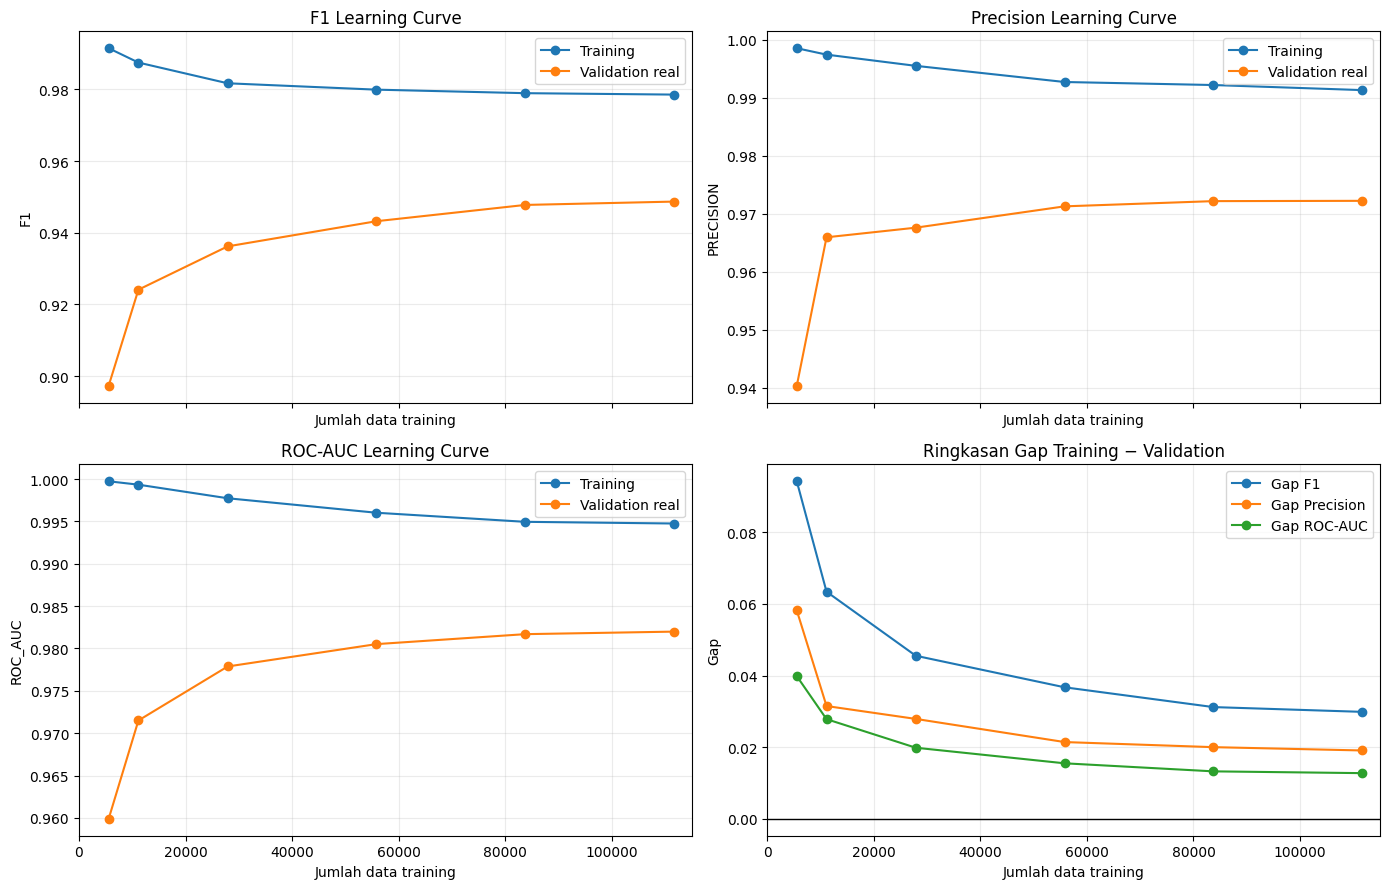

,ratio,train_size,gap_precision,gap_f1,gap_roc_auc,mean_absolute_gap
0,0.05,5582,5.82%,9.42%,3.98%,6.41%
1,0.10,11164,3.15%,6.34%,2.78%,4.09%
2,0.25,27910,2.79%,4.55%,1.99%,3.11%
3,0.50,55822,2.14%,3.67%,1.55%,2.46%
4,0.75,83734,2.00%,3.12%,1.33%,2.15%
5,1.00,111646,1.91%,2.99%,1.28%,2.06%


In [13]:
# Development split hostname-disjoint; final test tidak disentuh.
lc_train_parts,lc_val_parts=[],[]
for label in (0,1):
    part=real_train_base[real_train_base.label==label]
    splitter=GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEED+7)
    a,b=next(splitter.split(part,groups=part.host))
    lc_train_parts.append(part.iloc[a]); lc_val_parts.append(part.iloc[b])
lc_n=min(map(len,lc_train_parts)); lv_n=min(map(len,lc_val_parts))
lc_real_train=pd.concat([x.sample(lc_n,random_state=SEED) for x in lc_train_parts])
lc_real_val=pd.concat([x.sample(lv_n,random_state=SEED) for x in lc_val_parts])
assert set(lc_real_train.host).isdisjoint(set(lc_real_val.host))

lc_pool=pd.concat([lc_real_train[["url","label"]],
                   external_operational[["url","label"]],
                   synth_operational[["url","label"]]],ignore_index=True)
lc_vectorizer=TfidfVectorizer(analyzer="char",ngram_range=(3,5),min_df=3,
    max_features=120_000,sublinear_tf=True,dtype=np.float32)
X_lc_pool=lc_vectorizer.fit_transform(lc_pool.url.map(prepare_url))
X_lc_val=lc_vectorizer.transform(lc_real_val.url.map(prepare_url))

curve=[]
for ratio in [0.05,0.10,0.25,0.50,0.75,1.00]:
    indices=[]
    for label in (0,1):
        available=np.flatnonzero(lc_pool.label.to_numpy()==label)
        rng=np.random.default_rng(SEED+int(ratio*1000)+label)
        indices.extend(rng.choice(available,size=max(1,int(len(available)*ratio)),
                                  replace=False))
    indices=np.asarray(indices)
    model_lc=MultinomialNB(alpha=SELECTED_ALPHA).fit(
        X_lc_pool[indices],lc_pool.label.iloc[indices])
    train_probability=model_lc.predict_proba(X_lc_pool[indices])[:,1]
    validation_probability=model_lc.predict_proba(X_lc_val)[:,1]
    train_metric=metric_set(lc_pool.label.iloc[indices].to_numpy(),train_probability)
    validation_metric=metric_set(lc_real_val.label.to_numpy(),validation_probability)
    row={"ratio":ratio,"train_size":len(indices)}
    for metric in ["precision","recall","f1","roc_auc","pr_auc"]:
        row[f"train_{metric}"]=train_metric[metric]
        row[f"validation_{metric}"]=validation_metric[metric]
        row[f"gap_{metric}"]=train_metric[metric]-validation_metric[metric]
    curve.append(row)
learning_curve_results=pd.DataFrame(curve)

display(learning_curve_results[["ratio","train_size","train_precision",
    "validation_precision","gap_precision","train_f1","validation_f1",
    "gap_f1","train_roc_auc","validation_roc_auc","gap_roc_auc"]]
    .style.format({c:"{:.2%}" for c in learning_curve_results.columns if c!="train_size"}))

fig,axes=plt.subplots(2,2,figsize=(14,9),sharex=True)
panels=[("f1","F1 Learning Curve"),("precision","Precision Learning Curve"),
        ("roc_auc","ROC-AUC Learning Curve")]
for ax,(metric,title) in zip(axes.flat[:3],panels):
    ax.plot(learning_curve_results.train_size,learning_curve_results[f"train_{metric}"],
            marker="o",label="Training")
    ax.plot(learning_curve_results.train_size,learning_curve_results[f"validation_{metric}"],
            marker="o",label="Validation real")
    ax.set_title(title); ax.set_ylabel(metric.upper())
    ax.set_xlim(0,learning_curve_results.train_size.max()*1.03); ax.grid(alpha=.25); ax.legend()

gap_ax=axes.flat[3]
for metric,label in [("f1","Gap F1"),("precision","Gap Precision"),
                     ("roc_auc","Gap ROC-AUC")]:
    gap_ax.plot(learning_curve_results.train_size,
                learning_curve_results[f"gap_{metric}"],marker="o",label=label)
gap_ax.axhline(0,color="black",linewidth=1)
gap_ax.set_title("Ringkasan Gap Training − Validation")
gap_ax.set_ylabel("Gap"); gap_ax.set_xlim(0,learning_curve_results.train_size.max()*1.03)
gap_ax.grid(alpha=.25); gap_ax.legend()
for ax in axes.flat:
    ax.set_xlabel("Jumlah data training")
    ax.ticklabel_format(style="plain",axis="x")
plt.tight_layout(); plt.show()

gap_summary=learning_curve_results[["ratio","train_size","gap_precision",
                                    "gap_f1","gap_roc_auc"]].copy()
gap_summary["mean_absolute_gap"]=gap_summary[["gap_precision","gap_f1",
                                               "gap_roc_auc"]].abs().mean(axis=1)
display(gap_summary.style.format({"ratio":"{:.2f}","gap_precision":"{:.2%}",
    "gap_f1":"{:.2%}","gap_roc_auc":"{:.2%}","mean_absolute_gap":"{:.2%}"}))

**Interpretasi hasil multi-metrik:** ketika rasio meningkat dari 0,05 menjadi 1,00, gap F1 turun dari 9,42% menjadi 2,99%, gap ROC-AUC turun dari 3,98% menjadi 1,28%, dan gap precision turun dari 5,82% menjadi 1,91%. Pola gap yang menyempit menunjukkan tambahan data membantu stabilitas generalisasi.

Panel gap merupakan ringkasan overfitting yang lebih lengkap daripada F1 saja. ROC-AUC memiliki gap paling kecil pada ukuran data besar, berarti kemampuan ranking probabilitas lebih stabil daripada keputusan threshold. Sumbu X menunjukkan jumlah observasi training aktual, bukan rasio, sehingga hubungan antara volume data dan generalisasi dapat dibaca langsung.

### 14.1 Perbandingan Learning Curve Seluruh Model Naive Bayes

Perbandingan ini mengadopsi kelebihan notebook eksperimen sederhana, tetapi memakai development training dan validation nyata yang hostname-disjoint. Final real test tidak digunakan. Model teks memakai TF-IDF yang sama; GaussianNB memakai fitur numerik terstandardisasi; CategoricalNB memakai fitur numerik yang didiskretisasi.

,model,train_size,train_f1,validation_f1,gap
0,MultinomialNB,111646,97.86%,94.87%,2.99%
1,ComplementNB,111646,97.86%,94.87%,2.99%
2,CategoricalNB,111646,93.92%,91.05%,2.88%
3,BernoulliNB,111646,96.35%,88.43%,7.91%
4,GaussianNB,111646,72.16%,35.90%,36.26%


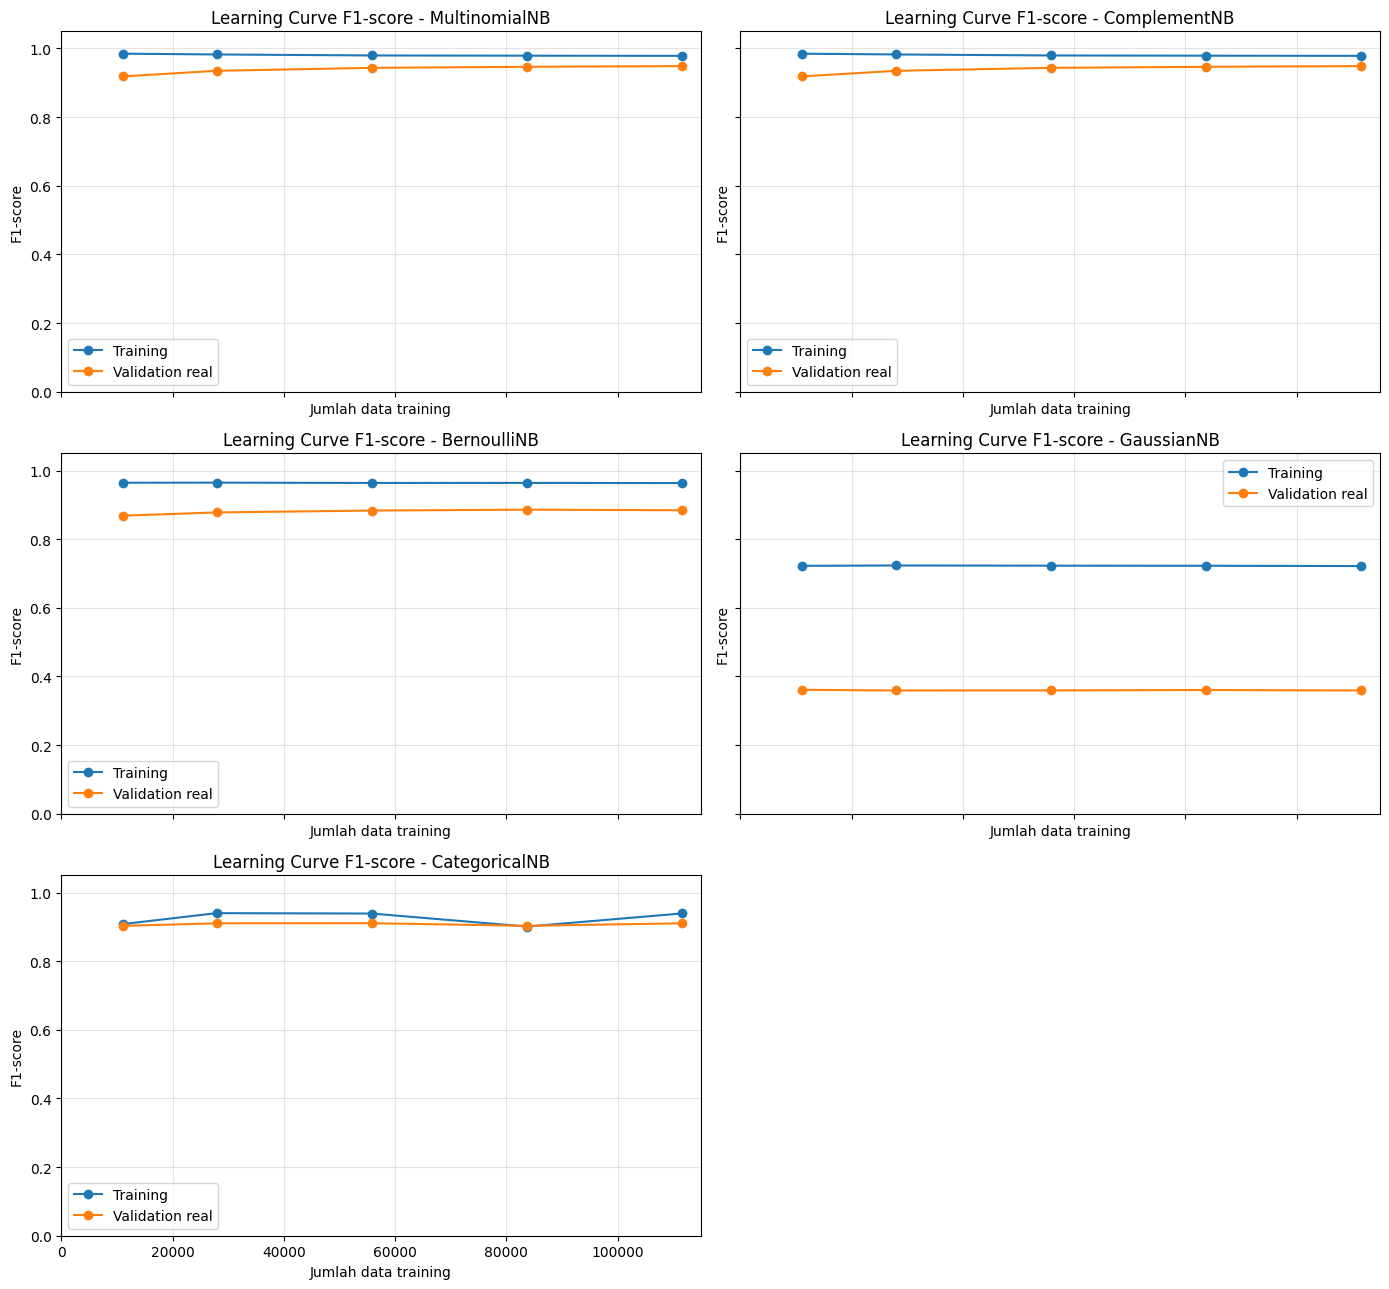

,model,train_size,train_f1,validation_f1,gap
0,MultinomialNB,111646,0.978572,0.948701,0.029871
1,ComplementNB,111646,0.978572,0.948701,0.029871
2,CategoricalNB,111646,0.939243,0.910469,0.028774
3,BernoulliNB,111646,0.963468,0.884327,0.079140
4,GaussianNB,111646,0.721610,0.358983,0.362626


In [14]:
# Learning curve F1 untuk lima model dengan subset seimbang yang identik.
import warnings
warnings.filterwarnings('ignore',category=UserWarning,
    module='sklearn.preprocessing._discretization')
all_lc_fractions=[0.10,0.25,0.50,0.75,1.00]
all_lc_indices={}
lc_labels=lc_pool.label.to_numpy()
for fraction in all_lc_fractions:
    selected_indices=[]
    for label in (0,1):
        available=np.flatnonzero(lc_labels==label)
        count=max(1,int(len(available)*fraction))
        selected_indices.extend(np.random.default_rng(
            SEED+5000+int(fraction*1000)+label).choice(
                available,size=count,replace=False))
    all_lc_indices[fraction]=np.asarray(selected_indices)

# Fitur numerik dihitung sekali; scaler/binner tetap di-fit ulang per subset.
lc_numeric_pool=np.asarray([numeric_url_features(x) for x in lc_pool.url],dtype=float)
lc_numeric_val=np.asarray([numeric_url_features(x) for x in lc_real_val.url],dtype=float)
all_model_curve=[]
for fraction,indices in all_lc_indices.items():
    y_subset=lc_labels[indices]
    y_validation=lc_real_val.label.to_numpy()

    text_models={
        'MultinomialNB':MultinomialNB(alpha=SELECTED_ALPHA),
        'ComplementNB':ComplementNB(alpha=SELECTED_ALPHA),
        'BernoulliNB':BernoulliNB(alpha=.05,binarize=.0)}
    for name,candidate in text_models.items():
        candidate.fit(X_lc_pool[indices],y_subset)
        train_prediction=candidate.predict(X_lc_pool[indices])
        validation_prediction=candidate.predict(X_lc_val)
        all_model_curve.append({
            'model':name,'fraction':fraction,'train_size':len(indices),
            'train_f1':f1_score(y_subset,train_prediction),
            'validation_f1':f1_score(y_validation,validation_prediction)})

    subset_scaler=StandardScaler()
    Xg_train=subset_scaler.fit_transform(lc_numeric_pool[indices])
    Xg_val=subset_scaler.transform(lc_numeric_val)
    gaussian_lc=GaussianNB(var_smoothing=1e-9).fit(Xg_train,y_subset)
    all_model_curve.append({
        'model':'GaussianNB','fraction':fraction,'train_size':len(indices),
        'train_f1':f1_score(y_subset,gaussian_lc.predict(Xg_train)),
        'validation_f1':f1_score(y_validation,gaussian_lc.predict(Xg_val))})

    subset_binner=KBinsDiscretizer(n_bins=10,encode='ordinal',strategy='quantile',
        quantile_method='averaged_inverted_cdf')
    Xc_train=subset_binner.fit_transform(lc_numeric_pool[indices]).astype(int)
    Xc_val=subset_binner.transform(lc_numeric_val).astype(int)
    categorical_lc=CategoricalNB(alpha=1.0).fit(Xc_train,y_subset)
    all_model_curve.append({
        'model':'CategoricalNB','fraction':fraction,'train_size':len(indices),
        'train_f1':f1_score(y_subset,categorical_lc.predict(Xc_train)),
        'validation_f1':f1_score(y_validation,categorical_lc.predict(Xc_val))})

all_model_learning_curve=pd.DataFrame(all_model_curve)
all_model_learning_curve['gap']=all_model_learning_curve.train_f1-all_model_learning_curve.validation_f1
all_model_learning_summary=(all_model_learning_curve.sort_values('fraction')
    .groupby('model',as_index=False).tail(1)
    .sort_values('validation_f1',ascending=False).reset_index(drop=True))
display(all_model_learning_summary[['model','train_size','train_f1','validation_f1','gap']]
        .style.format({'train_f1':'{:.2%}','validation_f1':'{:.2%}','gap':'{:.2%}'}))

fig,axes=plt.subplots(3,2,figsize=(14,13),sharex=True,sharey=True)
for ax,name in zip(axes.flat, ['MultinomialNB','ComplementNB','BernoulliNB',
                                'GaussianNB','CategoricalNB']):
    part=all_model_learning_curve[all_model_learning_curve.model==name]
    ax.plot(part.train_size,part.train_f1,marker='o',label='Training')
    ax.plot(part.train_size,part.validation_f1,marker='o',label='Validation real')
    ax.set_title('Learning Curve F1-score - '+name)
    ax.set_ylabel('F1-score'); ax.set_xlabel('Jumlah data training')
    ax.set_xlim(0,all_model_learning_curve.train_size.max()*1.03)
    ax.set_ylim(0,1.05); ax.ticklabel_format(style='plain',axis='x')
    ax.grid(alpha=.35); ax.legend()
axes.flat[-1].axis('off')
plt.tight_layout(); plt.show()

warnings.filterwarnings('default',category=UserWarning,
    module='sklearn.preprocessing._discretization')
all_model_learning_summary[['model','train_size','train_f1','validation_f1','gap']]

**Interpretasi hasil aktual:** pada 111.646 data development, MultinomialNB dan ComplementNB sama-sama mencapai F1 validation 94,87% dengan gap 2,99%. CategoricalNB mencapai 91,05% (gap 2,88%), BernoulliNB 88,43% (gap 7,91%), dan GaussianNB 35,90% (gap 36,26%). Hasil ini menegaskan bahwa MultinomialNB/ComplementNB paling sesuai untuk TF-IDF karakter. GaussianNB bukan hanya berkinerja rendah, tetapi juga mengalami gap sangat besar pada jalur numerik. MultinomialNB tetap dipilih karena hasil final real-only, dukungan threshold validation, dan integrasi model telah ditetapkan secara konsisten.

## 15. Ablation Study

Ablation mengisolasi pengaruh data sintetis. Arsitektur, rentang n-gram, alpha, threshold, dan final real test dibuat sama. Skenario ketiga memakai mixed test sebagai analisis tambahan, bukan pengganti klaim real-only.

,accuracy,precision,recall,f1,roc_auc,pr_auc
Real-only train → real-only test,95.85%,98.96%,92.68%,95.72%,98.92%,99.17%
Real+sintetis train → real-only test,95.45%,97.36%,93.43%,95.35%,98.39%,98.79%
Real+sintetis train → mixed test,98.22%,98.99%,97.43%,98.20%,99.75%,99.78%


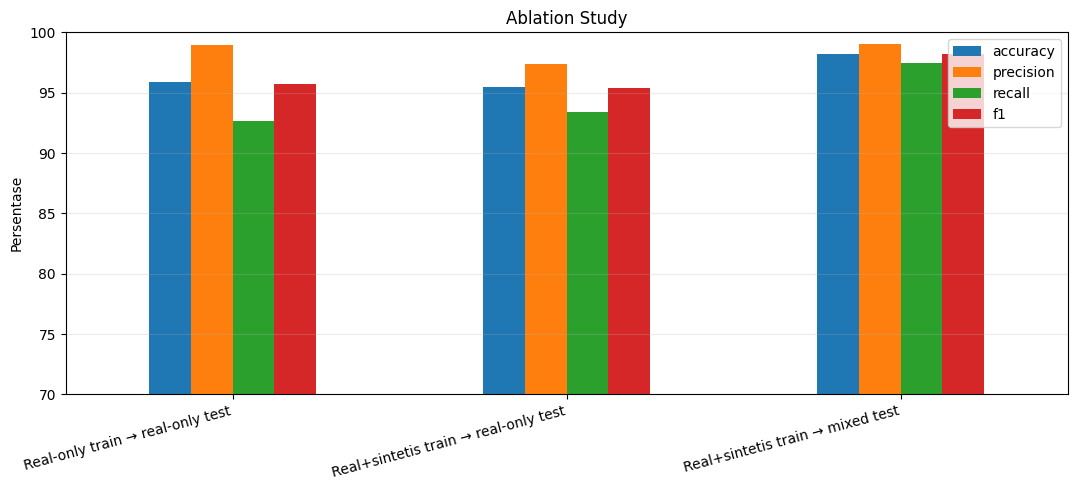

,accuracy,precision,recall,f1
Real-only train → real-only test,0.958521,0.989551,0.926829,0.957163
Real+sintetis train → real-only test,0.954482,0.973612,0.934286,0.953544
Real+sintetis train → mixed test,0.982174,0.989924,0.974265,0.982032


In [15]:
# A. Real-only training → real-only test
real_vectorizer=TfidfVectorizer(analyzer="char",ngram_range=(3,5),min_df=2,
    max_features=150_000,sublinear_tf=True,dtype=np.float32)
X_real_train=real_vectorizer.fit_transform(real_train.url.map(prepare_url))
X_real_test=real_vectorizer.transform(real_test.url.map(prepare_url))
real_model=MultinomialNB(alpha=.05).fit(X_real_train,real_train.label)
real_probability=real_model.predict_proba(X_real_test)[:,1]

ablation_results={
 "Real-only train → real-only test":
     metric_set(real_test.label.to_numpy(),real_probability),
 "Real+sintetis train → real-only test":
     results_real["MultinomialNB"],
 "Real+sintetis train → mixed test":
     results_mixed["MultinomialNB"]
}
ablation_table=pd.DataFrame(ablation_results).T
display(ablation_table[["accuracy","precision","recall","f1","roc_auc","pr_auc"]]
        .style.format("{:.2%}"))

plot_data=(ablation_table[["accuracy","precision","recall","f1"]]*100)
plot_data.plot(kind="bar",figsize=(11,5),ylim=(70,100))
plt.ylabel("Persentase"); plt.title("Ablation Study")
plt.xticks(rotation=15,ha="right"); plt.grid(axis="y",alpha=.25)
plt.tight_layout(); plt.show()

# Simpan hasil diagnostik agar laporan dan notebook konsisten.
evaluation_path=Path("models/evaluation.json")
diagnostic_report=json.loads(evaluation_path.read_text(encoding="utf-8"))
diagnostic_report["learning_curve"]=learning_curve_results.to_dict("records")
diagnostic_report["all_model_learning_curve"]=all_model_learning_curve.to_dict("records")
diagnostic_report["all_model_learning_summary"]=all_model_learning_summary.to_dict("records")
diagnostic_report["learning_gap_summary"]=gap_summary.to_dict("records")
diagnostic_report["threshold_optimization"]={"selected_threshold":SELECTED_THRESHOLD,"source":"hostname-disjoint real validation","precision_constraint":.94,"objective":"F1 + 0.10 recall","final_train_test_f1_gap":training_metrics["f1"]-results_real["MultinomialNB"]["f1"]}
diagnostic_report["ablation"]=ablation_results
evaluation_path.write_text(json.dumps(diagnostic_report,indent=2),encoding="utf-8")
ablation_table[["accuracy","precision","recall","f1"]]

**Interpretasi hasil aktual:** real-only memperoleh F1 95,72% dan recall 92,68%, sedangkan real+sintetis memperoleh F1 95,35% dan recall 93,43%. Jadi konfigurasi final menukar 0,37 poin F1 untuk tambahan recall 0,75 poin—trade-off yang relevan karena false negative phishing lebih berbahaya. Mixed-test F1 98,20% tetap hanya hasil pendukung.

### Keputusan model aplikasi final

**Model final adalah MultinomialNB dengan hard phishing augmentation, 50% synthetic-train, dan threshold validation 0,48.**

Threshold dipilih pada validation nyata hostname-disjoint dengan syarat precision minimal 94%, bukan dari final test. Model final mencapai Accuracy 95,45%, Precision 97,36%, Recall 93,43%, F1 95,35%, ROC-AUC 98,39%, dan PR-AUC 98,79% pada real-only test. Gap F1 training–test adalah 2,37 poin persentase. Model Joblib dan frontend menggunakan konfigurasi ini.

## 16. Kesimpulan

Optimasi dilakukan tanpa final-test leakage melalui normalized deduplication, hostname group split, validation nyata, hard phishing augmentation 10%, synthetic-train 50%, pembatasan TF-IDF (`min_df=3`, `max_features=120.000`), pencarian alpha, penalti generalization gap, dan threshold tuning. Threshold terpilih adalah 0,48.

Pada real-only test, model mencapai Accuracy 95,45%, Precision 97,36%, Recall 93,43%, F1 95,35%, ROC-AUC 98,39%, dan PR-AUC 98,79%. Training F1 97,72% menghasilkan gap 2,37 poin persentase. Mixed-test F1 98,20% hanya digunakan sebagai evaluasi pendukung.

Learning curve menunjukkan gap F1, precision, dan ROC-AUC mengecil ketika ukuran training meningkat. Audit external mengungkap domain shift yang kuat, sehingga seluruh data external tidak layak dimasukkan secara naif. Strategi hard phishing augmentation yang seimbang menurunkan gap dibanding model sebelumnya sambil menaikkan F1 holdout utama dari 95,04% menjadi 95,35%. Model real+sintetis dengan threshold validation dipilih sebagai model aplikasi final.